In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from scipy.sparse import csr_matrix
from sklearn.metrics import accuracy_score, classification_report

import experiment
import clslib
import analysis
import smlp
import loglin


In [2]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [5]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)

tfidf_encoder = clslib.TFIDF(bpe_tokenizer)

my_classifiers = OrderedDict()

In [6]:
# encoder test
texts = [
    "a good movie",
    "a bad movie",
    "a very good performance"
]

tfidf_encoder.fit(texts)

print(tfidf_encoder("a good movie"))
print("Dimensions:", len(tfidf_encoder))

[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.48133417 0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         

In [8]:
# tokenizer test
text = "A good good movie"

print(bpe_tokenizer.encode(text).tokens)
print(len(tfidf_encoder))

['▁', '[UNK]', '▁good', '▁good', '▁movie']
1000


In [9]:
my_classifiers['logistic_tfidf-enc'] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"

    my_classifiers['logistic_tfidf-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=tfidf_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            },
            fit_encoder=True
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\nl

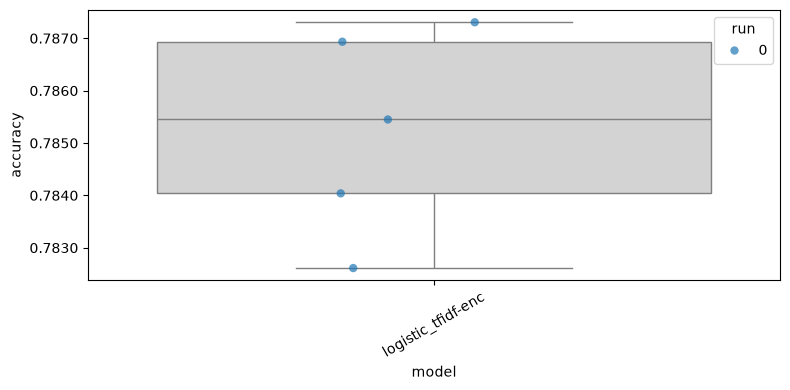

In [10]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [11]:
print(my_classifiers['logistic_tfidf-enc'][0]['accuracies'])

OrderedDict({0: 0.785449146250928, 1: 0.7840386043058649, 2: 0.7873051224944321, 3: 0.7869339272457313, 4: 0.7826119236765907})


In [ ]:
testing_sentences = test_dataset["sentence"]
testing_labels = test_dataset["label"]

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):
        fold_folder = (f"{results_folder}/logistic_tfidf-enc/seed-{seed}/fold-{fold}")

        # Load the IDF weights learned on this fold
        tfidf_encoder.load(fold_folder / "tfidf_idf.npy")

        # Load the corresponding trained classifier
        model = loglin.load(fold_folder / "model")

        predictions = loglin.predict(
            testing_sentences, model, tfidf_encoder
        )

        print(f"Seed {seed}, fold {fold}:")
        print(f"Test accuracy: {accuracy_score(testing_labels, predictions):.4f}")

In [12]:
testing_sentences = test_dataset["sentence"]
testing_labels = test_dataset["label"]

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):
        model_path = f"{results_folder}/logistic_tfidf-enc/seed-{seed}/fold-{fold}/model"
        idf_path = f"{results_folder}/logistic_tfidf-enc/seed-{seed}/fold-{fold}/tfidf_idf.npy"

        tfidf_encoder.load(idf_path)
        model = loglin.load(model_path)
        predictions = loglin.predict(
            testing_sentences, model, tfidf_encoder
        )

        print(f"Seed {seed}, fold {fold}:")
        print(f"Test accuracy: {accuracy_score(testing_labels, predictions):.4f}")

Seed 0, fold 0:
Test accuracy: 0.7580
Seed 0, fold 1:
Test accuracy: 0.7569
Seed 0, fold 2:
Test accuracy: 0.7626
Seed 0, fold 3:
Test accuracy: 0.7615
Seed 0, fold 4:
Test accuracy: 0.7592


In [13]:
# save results
df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)